**Practica 4**

*K fold cross validacion*

$K = 4$ con shuffle
$C = [0.1, 0.2, 0.3]$

Para $C = 0.1$ hace un experimento con $K_1$ y luego con los demas C

*LOO*
$K = N$



**Validación Cruzada**

In [2]:
import numpy as np; from sklearn.model_selection import KFold
X = np.arange(10); kf = KFold(n_splits=5, shuffle=True, random_state=23)
for i, (X_train_ind, X_valid_ind) in enumerate(kf.split(X)):
 print(f"Split {i}: {X_train_ind} {X_valid_ind}")


Split 0: [0 1 2 3 4 6 7 9] [5 8]
Split 1: [0 1 3 4 5 6 7 8] [2 9]
Split 2: [0 1 2 3 5 6 8 9] [4 7]
Split 3: [2 3 4 5 6 7 8 9] [0 1]
Split 4: [0 1 2 4 5 7 8 9] [3 6]


In [4]:

import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 400; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)


Tiempo (hh:mm:ss): 00:05:40


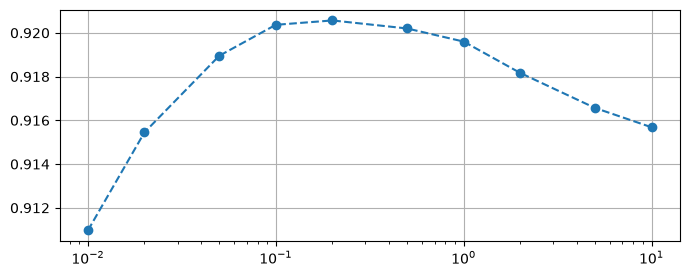

In [5]:

import matplotlib.pyplot as plt; 
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression; 
import time; 
start = time.time()

Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10]); 

acc = np.zeros_like(Cs)

for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=4).mean()
    
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))
plt.figure(figsize=(8, 3)); plt.grid(); plt.semilogx(Cs, acc, 'o--');


Tiempo (hh:mm:ss): 00:04:19


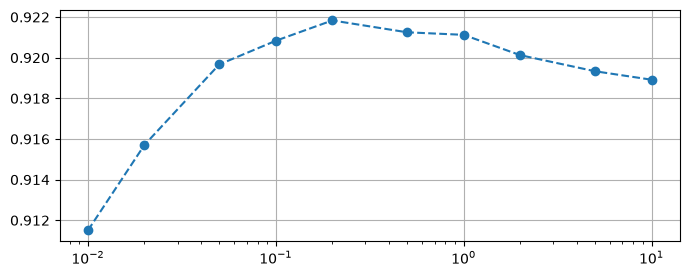

In [ ]:
import matplotlib.pyplot as plt; 
from sklearn.model_selection import ShuffleSplit, cross_val_score
from sklearn.linear_model import LogisticRegression; 
import time; start = time.time()
Cs = np.array([.01, .02, .05, .1, .2, .5, 1, 2, 5, 10]); 
acc = np.zeros_like(Cs)
splitter = ShuffleSplit(n_splits=4, test_size=0.1, random_state=23) # lo que hace es split en 4 con 10% de los datos y un aleatorio no aleatorio
for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=splitter).mean()
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))
plt.figure(figsize=(8, 3)); 
plt.grid(); 
plt.semilogx(Cs, acc, 'o--')

**Ejercicio Con Fashion MNIST**

In [7]:
#cargar database


import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 400; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)

c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

Tiempo (hh:mm:ss): 00:04:00


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


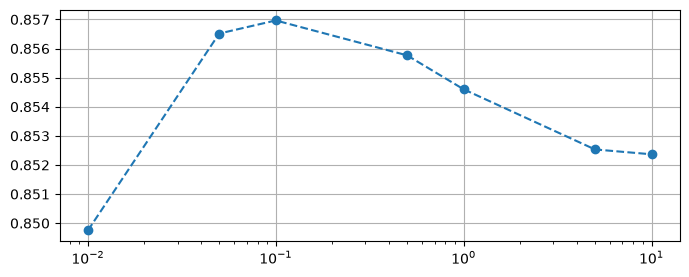

In [8]:
# cross_val_score y LogisticRegresion


import matplotlib.pyplot as plt; 
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression; 
import time; 
start = time.time()

Cs = np.array([.01, .05, .1, .5, 1, 5, 10])

acc = np.zeros_like(Cs)

for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=4).mean()
    
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))
plt.figure(figsize=(8, 3)); plt.grid(); plt.semilogx(Cs, acc, 'o--')

c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

Tiempo (hh:mm:ss): 00:05:41


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


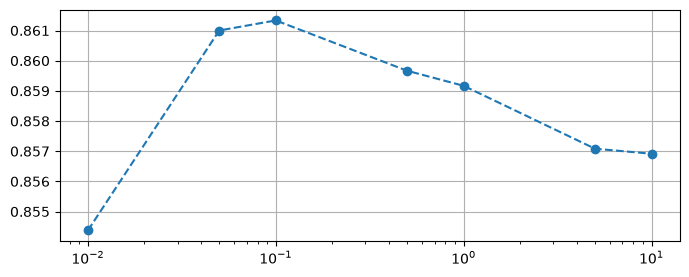

In [10]:
#con shuffle split - 

import matplotlib.pyplot as plt; 
from sklearn.model_selection import ShuffleSplit, cross_val_score
from sklearn.linear_model import LogisticRegression; 
import time; start = time.time()
Cs = np.array([.01, .05, .1, .5, 1, 5, 10]); 
acc = np.zeros_like(Cs)
splitter = ShuffleSplit(n_splits=4, test_size=0.1, random_state=23) # lo que hace es split en 4 con 10% de los datos y un aleatorio no aleatorio
for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=splitter).mean()
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))
plt.figure(figsize=(8, 3)); 
plt.grid(); 
plt.semilogx(Cs, acc, 'o--')

**Ejercicios con CIFAR 10**

In [12]:
#cargar database


import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy")
X_train = ds['train'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 400; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)

c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

Tiempo (hh:mm:ss): 00:03:47


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


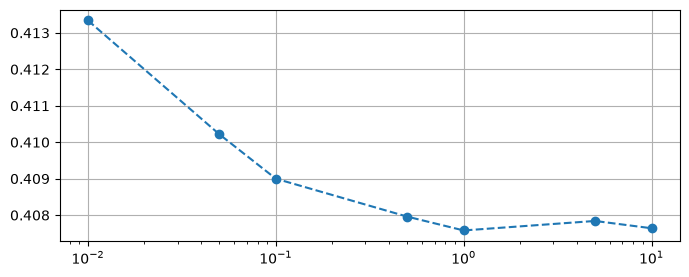

In [13]:
# cross_val_score y LogisticRegresion


import matplotlib.pyplot as plt; 
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression; 
import time; 
start = time.time()

Cs = np.array([.01, .05, .1, .5, 1, 5, 10])

acc = np.zeros_like(Cs)

for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=4).mean()
    
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))
plt.figure(figsize=(8, 3)); plt.grid(); plt.semilogx(Cs, acc, 'o--')

c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/pre

Tiempo (hh:mm:ss): 00:04:28


c:\Users\saxon\2027_02_28_APA2627\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


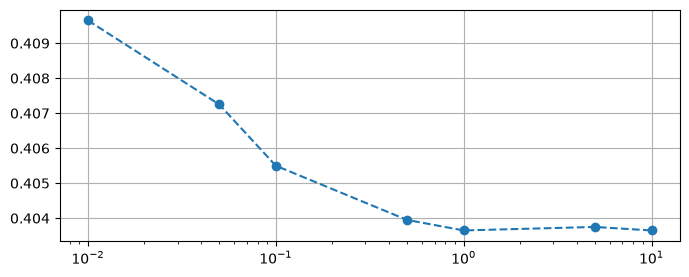

In [14]:
#con shuffle split - cross validacion tipo mas flexible 

import matplotlib.pyplot as plt; 
from sklearn.model_selection import ShuffleSplit, cross_val_score
from sklearn.linear_model import LogisticRegression; 
import time; start = time.time()
Cs = np.array([.01, .05, .1, .5, 1, 5, 10]); 
acc = np.zeros_like(Cs)
splitter = ShuffleSplit(n_splits=4, test_size=0.1, random_state=23) # lo que hace es split en 4 con 10% de los datos y un aleatorio no aleatorio
for i, C in enumerate(Cs):
    acc[i] = cross_val_score(LogisticRegression(C=C, max_iter=200), X_train, y_train, cv=splitter).mean()
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))
plt.figure(figsize=(8, 3)); 
plt.grid(); 
plt.semilogx(Cs, acc, 'o--')

#grid search ajusta C y max_iter a la vez

In [15]:
import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("ylecun/mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 400; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)


In [18]:

import warnings; warnings.filterwarnings('ignore'); from sklearn.model_selection import ShuffleSplit, GridSearchCV
from sklearn.linear_model import LogisticRegression; import time; start = time.time()
clf = LogisticRegression(); G = {"C": [.01, 0.02, .05, .1, 2, 1, 5, 10], "max_iter": [100, 200, 300]}
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)
GS = GridSearchCV(clf, G, scoring='accuracy', n_jobs=-1, cv=splitter, pre_dispatch=8) #quiere ver el accuracy y usa los valores optimos para enrtenar un cierto modelo 
acc = GS.fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión: {acc:.1%} con {GS.best_params_}")
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

Precisión: 92.6% con {'C': 0.1, 'max_iter': 100}
Tiempo (hh:mm:ss): 00:00:52


In [ ]:
#randomized, con n_iter, en vex de coger todas las combinaciones todo todos los hiperparametros, hace solo n_iter = 10. asumo que no me va a dar tiempo, pruebo unas y me quedo con la mejor
from sklearn.model_selection import RandomizedSearchCV; import time; start = time.time()
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)
GS = RandomizedSearchCV(clf, G, n_iter=10, scoring='accuracy', n_jobs=-1, cv=splitter, pre_dispatch=8) #pre dispatch lanza muchos a la vez si la maquina lo soporta
acc = GS.fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión: {acc:.1%} con {GS.best_params_}")
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))


Precisión: 92.6% con {'max_iter': 200, 'C': 0.1}
Tiempo (hh:mm:ss): 00:00:19


Ejercicio: reproduce el experimento de exploración de hiperparámetros con MNIST en Fashion-MNIST con y
CIFAR-10 con $K = 600, K = 1000$

Fashion MNIST

In [24]:
#cargar database


import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("zalando-datasets/fashion_mnist").with_format("numpy")
X_train = ds['train'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['image'].astype(np.float32).reshape(-1, 28*28) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 600; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)

In [25]:
import warnings; warnings.filterwarnings('ignore'); from sklearn.model_selection import ShuffleSplit, GridSearchCV
from sklearn.linear_model import LogisticRegression; import time; start = time.time()
clf = LogisticRegression(); G = {"C": [.01, 0.02, .05, .1, 2, 1, 5, 10], "max_iter": [100, 200, 300]}
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)
GS = GridSearchCV(clf, G, scoring='accuracy', n_jobs=-1, cv=splitter, pre_dispatch=8) #quiere ver el accuracy y usa los valores optimos para enrtenar un cierto modelo 
acc = GS.fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión: {acc:.1%} con {GS.best_params_}")
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

Precisión: 84.5% con {'C': 0.05, 'max_iter': 300}
Tiempo (hh:mm:ss): 00:02:24


In [26]:
#randomized, con n_iter, en vex de coger todas las combinaciones todo todos los hiperparametros, hace solo n_iter = 10. asumo que no me va a dar tiempo, pruebo unas y me quedo con la mejor
from sklearn.model_selection import RandomizedSearchCV; import time; start = time.time()
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)
GS = RandomizedSearchCV(clf, G, n_iter=10, scoring='accuracy', n_jobs=-1, cv=splitter, pre_dispatch=8) #pre dispatch lanza muchos a la vez si la maquina lo soporta
acc = GS.fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión: {acc:.1%} con {GS.best_params_}")
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

Precisión: 84.5% con {'max_iter': 300, 'C': 0.05}
Tiempo (hh:mm:ss): 00:01:18


CIFAR 10

In [27]:
#cargar database


import numpy as np; import datasets; from sklearn.decomposition import PCA
ds = datasets.load_dataset("uoft-cs/cifar10").with_format("numpy")
X_train = ds['train'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_train = ds['train'][:]['label'].astype(np.uint8)
X_test = ds['test'][:]['img'].astype(np.float32).reshape(-1, 32*32*3) / 255.
y_test = ds['test'][:]['label'].astype(np.uint8)
K = 1000; pca = PCA(n_components=K); X_train = pca.fit_transform(X_train); X_test = pca.transform(X_test)

In [29]:
import warnings; warnings.filterwarnings('ignore'); from sklearn.model_selection import ShuffleSplit, GridSearchCV
from sklearn.linear_model import LogisticRegression; import time; start = time.time()
clf = LogisticRegression(); G = {"C": [.01, 0.02, .05, .1, 2, 1, 5, 10], "max_iter": [100, 200, 300]}
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)
GS = GridSearchCV(clf, G, scoring='accuracy', n_jobs=-1, cv=splitter, pre_dispatch=8) #quiere ver el accuracy y usa los valores optimos para enrtenar un cierto modelo 
acc = GS.fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión: {acc:.1%} con {GS.best_params_}")
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

Precisión: 41.7% con {'C': 0.01, 'max_iter': 200}
Tiempo (hh:mm:ss): 00:03:34


In [30]:
#randomized, con n_iter, en vex de coger todas las combinaciones todo todos los hiperparametros, hace solo n_iter = 10. asumo que no me va a dar tiempo, pruebo unas y me quedo con la mejor
from sklearn.model_selection import RandomizedSearchCV; import time; start = time.time()
splitter = ShuffleSplit(n_splits=2, test_size=0.1, random_state=23)
GS = RandomizedSearchCV(clf, G, n_iter=10, scoring='accuracy', n_jobs=-1, cv=splitter, pre_dispatch=8) #pre dispatch lanza muchos a la vez si la maquina lo soporta
acc = GS.fit(X_train, y_train).score(X_test, y_test)
print(f"Precisión: {acc:.1%} con {GS.best_params_}")
print('Tiempo (hh:mm:ss):', time.strftime('%H:%M:%S', time.gmtime(time.time() - start)))

Precisión: 41.7% con {'max_iter': 300, 'C': 0.01}
Tiempo (hh:mm:ss): 00:01:41
